# Entrega N°1 - Proyecto Final

Para este proyecto seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

### Importar el Dataset del repositorio de UCI

In [9]:
# pip install ucimlrepo

# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 
  
# data (as pandas dataframes) 
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets 


### Librerías

In [10]:
# !pip install -q imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Apariencia de tablas y gráficas
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Semilla para que todos obtengamos los mismos resultados
SEMILLA = 20
np.random.seed(SEMILLA)

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


### Visualización de los datos

In [11]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


In [12]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [13]:
resumen(dataset)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Gender,str,2111,0,0.000,2,Female
Age,float64,2111,0,0.000,1402,21.000
Height,float64,2111,0,0.000,1574,1.620
Weight,float64,2111,0,0.000,1525,64.000
family_history_with_overweight,str,2111,0,0.000,2,yes
FAVC,str,2111,0,0.000,2,no
FCVC,float64,2111,0,0.000,810,2.000
NCP,float64,2111,0,0.000,635,3.000
CAEC,str,2111,0,0.000,4,Sometimes
SMOKE,str,2111,0,0.000,2,no


### Validación de relación entre IMC y Target

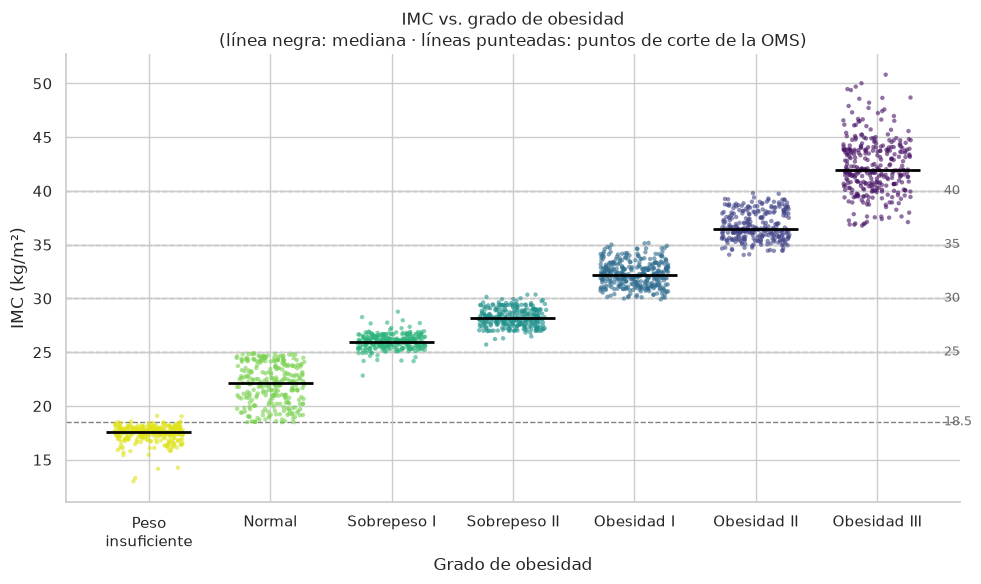

In [14]:
dataset['IMC'] = dataset['Weight'] / dataset['Height']**2

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, 7))

fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, (clase, color) in enumerate(zip(orden, colores)):
    imc = dataset.loc[dataset['NObeyesdad'] == clase, 'IMC']
    x = i + rng.uniform(-0.28, 0.28, len(imc))   # dispersión horizontal para que no se encimen
    ax.scatter(x, imc, s=10, color=color, alpha=0.6, edgecolor='none')
    ax.hlines(imc.median(), i - 0.35, i + 0.35, color='black', linewidth=2)   # mediana

# Puntos de corte de la OMS
for v in [18.5, 25, 30, 35, 40]:
    ax.axhline(v, color='gray', linestyle='--', linewidth=1, zorder=0)
    ax.text(6.55, v, f'{v}', va='center', fontsize=9, color='dimgray')

ax.set_xticks(range(7), etiquetas)
ax.set_xlabel('Grado de obesidad')
ax.set_ylabel('IMC (kg/m²)')
ax.set_title('IMC vs. grado de obesidad\n(línea negra: mediana · líneas punteadas: puntos de corte de la OMS)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Válidación de balance de clases

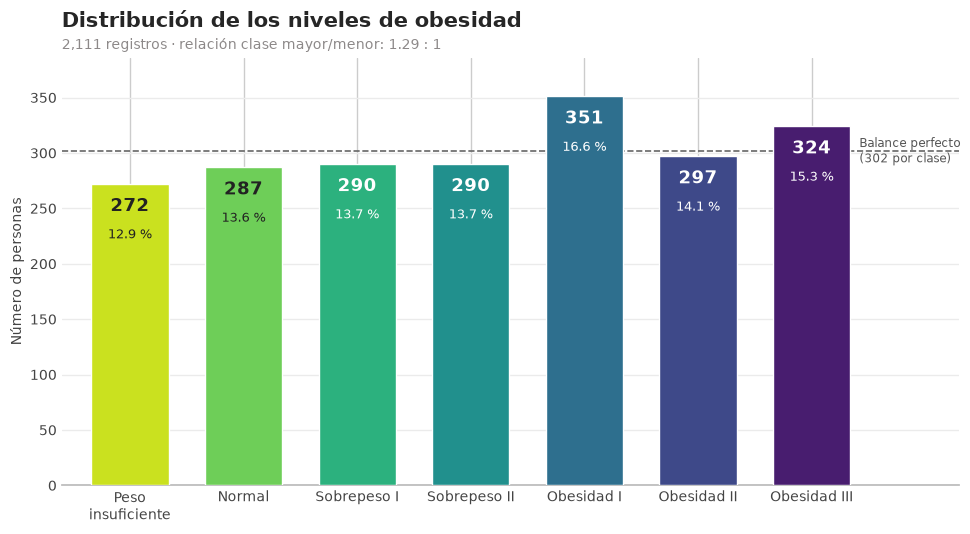

In [20]:
import numpy as np
import matplotlib.pyplot as plt

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
conteo = dataset['NObeyesdad'].value_counts().reindex(orden)
porcentaje = conteo / len(dataset) * 100

# Paleta ordenada: de amarillo-verde (peso bajo) a morado (obesidad III)
colores = plt.cm.viridis_r(np.linspace(0.08, 0.92, len(orden)))

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(etiquetas, conteo.values, color=colores, width=0.68, zorder=3)

# Número y porcentaje dentro de cada barra
for barra, n, p, c in zip(barras, conteo.values, porcentaje.values, colores):
    x = barra.get_x() + barra.get_width() / 2
    lum = 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
    texto = '#222222' if lum > 0.55 else 'white'      # texto oscuro en barras claras
    ax.text(x, n - 12, f'{n}', ha='center', va='top', fontsize=13, fontweight='bold', color=texto, zorder=5)
    ax.text(x, n - 40, f'{p:.1f} %', ha='center', va='top', fontsize=9.5, color=texto, zorder=5)

# Línea de balance perfecto (queda detrás de las barras)
ideal = len(dataset) / len(orden)
ax.axhline(ideal, color='#666666', linestyle='--', linewidth=1.2, zorder=2)
ax.text(6.42, ideal, f'Balance perfecto\n({ideal:.0f} por clase)', va='center', fontsize=8.5, color='#555555')

ax.set_title('Distribución de los niveles de obesidad', fontsize=15, fontweight='bold', loc='left', pad=22)
ax.text(0, 1.02, f'{len(dataset):,} registros · relación clase mayor/menor: {conteo.max()/conteo.min():.2f} : 1',
        transform=ax.transAxes, fontsize=10, color="#8D8989")
ax.set_ylabel('Número de personas', fontsize=10, color='#444444')
ax.set_ylim(0, conteo.max() * 1.1)
ax.set_xlim(-0.6, 7.3)
ax.grid(axis='y', color='#ebebeb', zorder=0)
ax.tick_params(axis='both', length=0, labelsize=10, colors='#444444')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#bbbbbb')
plt.tight_layout()
plt.show()

El dataset está balanceado. La clase más grande (Obesidad I) tiene apenas 1,29 veces los registros de la más pequeña (Peso insuficiente). Todas quedan cerca del 14,3 % que tendría un balance perfecto, que es la línea punteada de la gráfica.

### Análisis univariado de las variables númericas

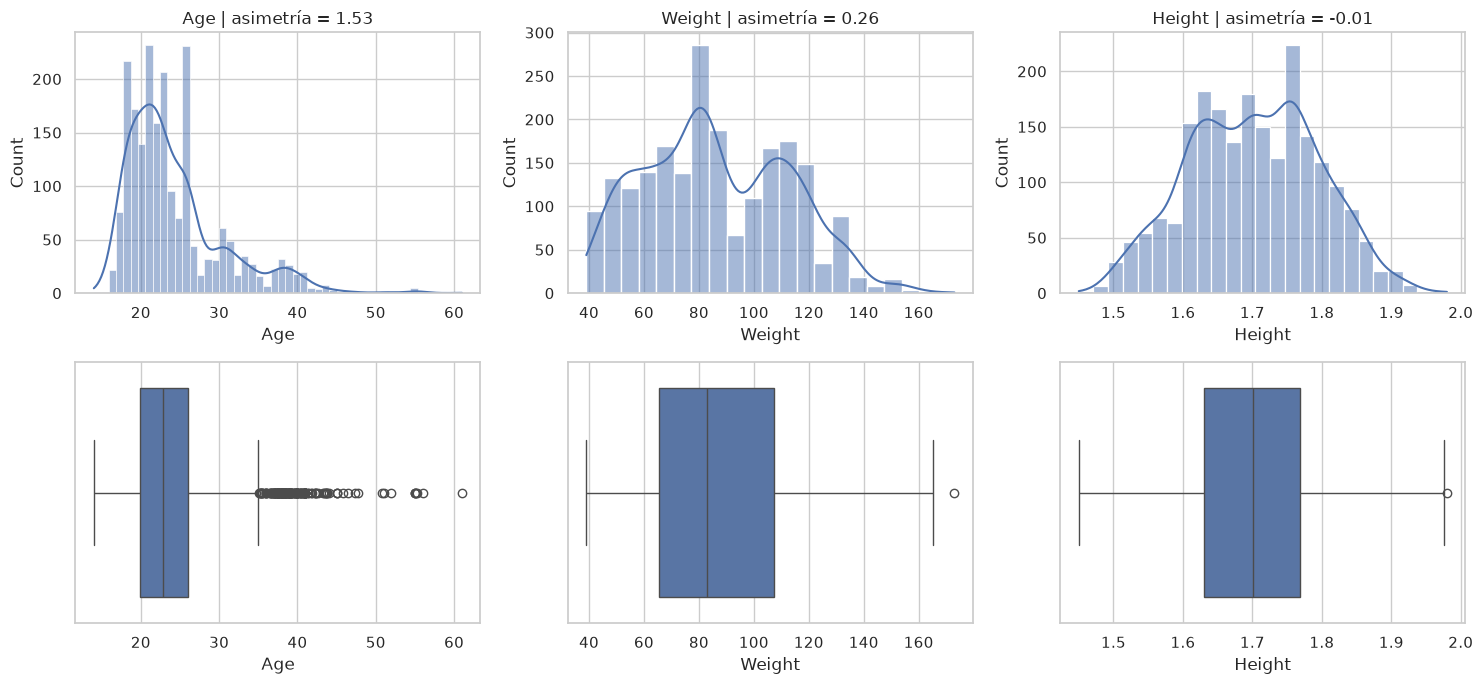

In [22]:
numericas = ["Age", "Weight", "Height"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(numericas):
    sns.histplot(dataset[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} | asimetría = {dataset[col].skew():.2f}")
    sns.boxplot(x=dataset[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

#### Observaciones

- *Age* tiene asimetría positiva fuerte (1,53). La mayoría de los encuestados son jóvenes: el 76 % tiene 26 años o menos y la mediana es 22,8. La cola se extiende hasta 61 años. El boxplot marca 168 valores atípicos, todos por encima de unos 35 años. No son errores: son personas mayores que simplemente son pocas en la muestra, así que no hay que eliminarlas. Para el informe, esto significa que los resultados representan sobre todo a población joven.
- *Weight* es casi simétrica (0,26), pero tiene varios picos. Eso tiene sentido, porque mezcla personas de 7 niveles de peso distintos. Solo hay un atípico, de 173 kg, y es un valor plausible.
- *Height* es prácticamente normal (−0,01), con una forma de campana centrada en 1,70 m y sin atípicos relevantes.

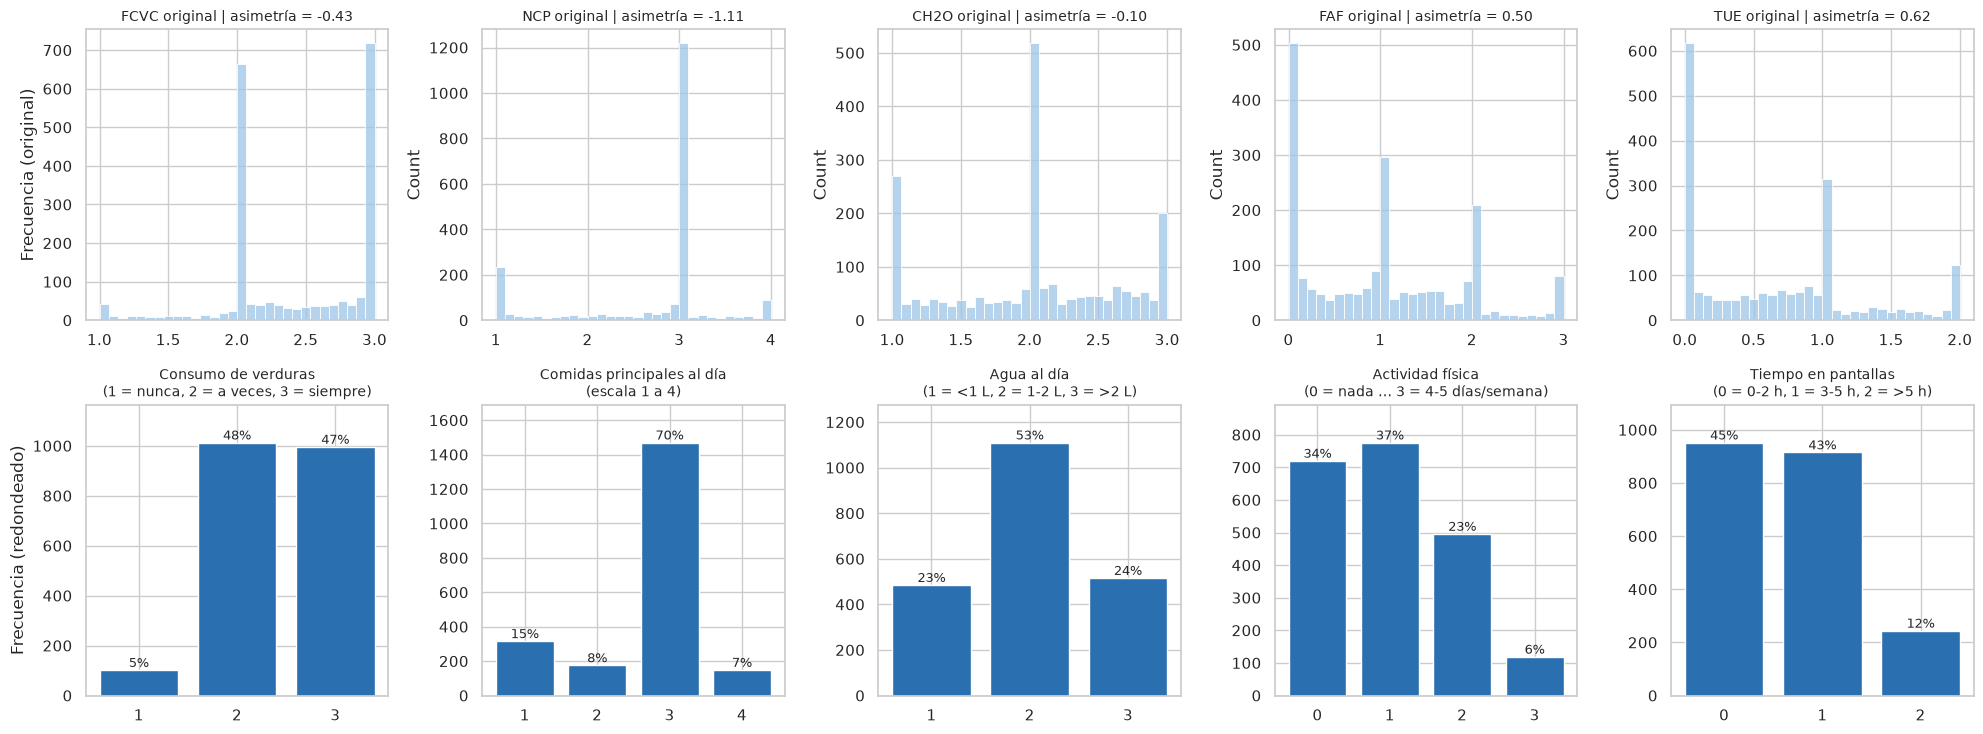

In [ ]:
ordinales = {
    "FCVC": "Consumo de verduras\n(1 = nunca, 2 = a veces, 3 = siempre)",
    "NCP":  "Comidas principales al día\n(escala 1 a 4)",
    "CH2O": "Agua al día\n(1 = <1 L, 2 = 1-2 L, 3 = >2 L)",
    "FAF":  "Actividad física\n(0 = nada … 3 = 4-5 días/semana)",
    "TUE":  "Tiempo en pantallas\n(0 = 0-2 h, 1 = 3-5 h, 2 = >5 h)",
}

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for i, (col, titulo) in enumerate(ordinales.items()):
    # Fila 1: valores originales (con decimales sintéticos)
    sns.histplot(dataset[col], bins=30, ax=axes[0, i], color='#9ec5e8')
    axes[0, i].set_title(f"{col} original | asimetría = {dataset[col].skew():.2f}", fontsize=10)
    axes[0, i].set_xlabel('')

    # Fila 2: valores redondeados a la escala de la encuesta
    conteo = dataset[col].round().astype(int).value_counts().sort_index()
    barras = axes[1, i].bar(conteo.index.astype(str), conteo.values, color='#2a6fb0')
    axes[1, i].bar_label(barras, labels=[f'{v/len(dataset):.0%}' for v in conteo.values], fontsize=9)
    axes[1, i].set_title(titulo, fontsize=10)
    axes[1, i].set_ylim(0, conteo.max() * 1.15)

axes[0, 0].set_ylabel('Frecuencia (original)')
axes[1, 0].set_ylabel('Frecuencia (redondeado)')
plt.tight_layout(); plt.show()


#### Observaciones

- *FCVC, verduras*: casi nadie dice “nunca” (5 %). El resto se reparte entre “a veces” (48 %) y “siempre” (47 %).
NCP, comidas al día: la gran mayoría responde 3 (70 %). Es la variable menos variada, así que probablemente aporte poco para distinguir clases.
- *CH2O, agua*: la distribución es la más equilibrada. La mitad toma entre 1 y 2 litros (53 %).
- *FAF, actividad física*: el 34 % no hace nada de ejercicio y solo el 6 % hace 4 o 5 días por semana. Puede ser de las variables más útiles para el modelo.
- *TUE, pantallas*: la mayoría pasa 0–2 h (45 %) o 3–5 h (43 %) frente a pantallas, y solo el 12 % más de 5 h.